tip: to replace character in vscode  

Ctrl F  
press arrow pointing right on the left of the fild to write the word to search  
on field up paste current char, down write new char  
on right of bottom field, click rightmost icon, replace all

tip: comment whole block  

select lines i want, Ctrl Shift 7  

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit

/home/gea/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


### Get data

In [2]:
d = np.array([5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0])
T = np.array([28.6, 27.8, 26.9, 25.9, 25.0, 24.0, 23.1])

sigma_d = np.full(d.shape, 1)
sigma_T = np.full(T.shape, 2)

### Define func

In [3]:
def line(x, m, q):
    """Modello di fit lineare."""
    return m * x + q

In [4]:
def period_model(d, l):
    """Modello per il periodo del pendolo."""
    return 2.0 * np.pi * np.sqrt((l**2.0 / 12.0 + d**2.0) / (9.81 * d))

In [5]:
def exponential(x, a, b):
    return a * np.exp(b * x)

### Plot

In [6]:
# Data i need to plot

x = d
y = T  
sigma_x = sigma_d/10
sigma_y = sigma_T/20  
model = line

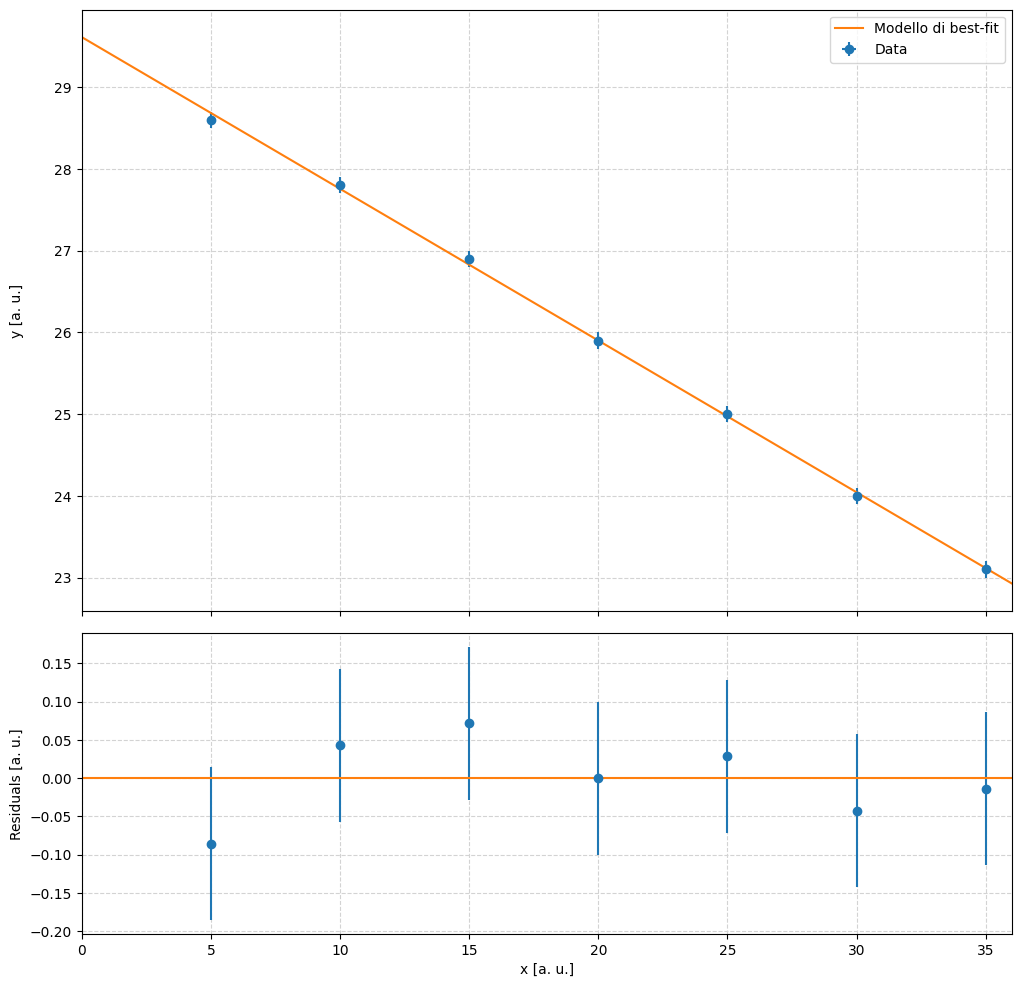

In [7]:
# Fit
popt, pcov = curve_fit(model, x, y, sigma=sigma_y)
res = y - model(x, *popt)

# Create the main figure
fig = plt.figure(figsize=(12, 12))
ax1, ax2 = fig.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))
x_lim = max(x)+1
xgrid = np.linspace(0.0, x_lim, 100)

# Main plot: the scatter plot of x vs. y, on the top panel.
ax1.errorbar(x, y, xerr=sigma_x, yerr=sigma_y, fmt='o', label='Data')
ax1.plot(xgrid, model(xgrid, *popt), label='Modello di best-fit')

# And now the residual plot, on the bottom panel.
ax2.errorbar(x, res, sigma_y, fmt='o')
ax2.plot(xgrid, np.full(xgrid.shape, 0.0)) # horizontal line at y=0

# STYLING  

ax1.set_ylabel('y [a. u.]')
ax1.grid(color='lightgray', ls='dashed')
ax1.legend()

ax2.set_xlabel('x [a. u.]')
ax2.set_ylabel('Residuals [a. u.]')
ax2.grid(color='lightgray', ls='dashed')

plt.xlim(0.0, x_lim)
fig.align_ylabels((ax1, ax2))

plt.show()

In [8]:
# Print results  

print(f'Parameters: {popt}')
print(f'Errors: {np.sqrt(np.diag(pcov))}')

Parameters: [-0.18571429 29.61428571]
Errors: [0.00221313 0.04948716]


### Chi test

In [9]:
chisq = np.sum((res / sigma_y)**2)
dof = len(y) - len(popt)
chi2_red = chisq / dof  # must give 1  

print(f'Chi: {chisq}')
print(f'Dof: {dof}')
print(f'Chi reduced: {chi2_red}')

Chi: 1.7142857142856718
Dof: 5
Chi reduced: 0.34285714285713437


note: call it chisq, not chi2, or will have problems later

TO compute chi square

residuals = [df.v0 - exp_decay(timestamp_val, *popt) for timestamp_val in df.t]

this formula for residuals is WRONG!!! it gives me a chi sqaure way too high  

residuals = df.v0 - exp_decay(df.t, *popt)   
this is right


**Notes * operator**

popt is an array of values  

$f(popt)$   
essentially it means:  
[f(x) for x in popt]  
means f needs in input a single value  
i get in output an array where in each position there is the repsective value of popt after having f applied  
being able to give directly popt as input means the function f is vectorized  
so means it's more efficidnt, don't need a for loop, it computes all the values at the same time  


$f(*popt)$  
essentially it means:  
f(popt[0], popt[1]...)  
means f requires in input a list of values, ofsame length as popt  
so f does oly one iteration, using values in popt those he wants  
this is not vectorization, bc don't improve speed, it's simply how python works that allows it   

popt: optimal params  
pcov: params covariance  

### P-value

rem, p-value is the right-tail probability, not the left  
so the prob of getting chi bigger next time   
so 1-CDF, not CDF  

the tables on the book are backwards, those give left probability  

In [2]:
from scipy.stats import chi2

dof = 8
chisq = 35.4

p_value = chi2.sf(chisq, dof)
print(f"P-value: {p_value}")

P-value: 2.2604913561492154e-05


In [11]:
# Other method: prob of getting chi smaller next time, then get the opposite  

import scipy.stats

p_rev = scipy.stats.chi2.cdf(chisq, dof)
p = 1-p_rev
print(p)

0.25126826457787876
